In [1]:
import os, sys, json
PROJECT_ROOT = os.path.abspath("..")
sys.path.append(PROJECT_ROOT)
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.covariance import LedoitWolf
from src.data import load_split, make_dataset

train_df, val_df, test_df = load_split(PROJECT_ROOT)
model = keras.models.load_model(os.path.join(PROJECT_ROOT, "models", "final_efficientnetb0.keras"))
emb = keras.Model(model.input, model.get_layer("global_average_pooling2d").output)

def embed(df):
    return emb.predict(make_dataset(df, batch_size=32), verbose=0)

Ftr, Fva, Fte = embed(train_df), embed(val_df), embed(test_df)

lw = LedoitWolf().fit(Ftr)
mu, P = Ftr.mean(0), lw.precision_
def dist(F):
    d = F - mu
    return np.sqrt(np.einsum("ij,jk,ik->i", d, P, d))

dva, dte = dist(Fva), dist(Fte)
for q in [50, 90, 95, 99, 100]:
    print(f"val dist p{q}: {np.percentile(dva, q):.1f} | test p{q}: {np.percentile(dte, q):.1f}")
np.savez(os.path.join(PROJECT_ROOT, "models", "ood_stats.npz"), mu=mu, P=P)

val dist p50: 31.4 | test p50: 31.0
val dist p90: 47.1 | test p90: 48.8
val dist p95: 54.5 | test p95: 55.7
val dist p99: 69.0 | test p99: 69.7
val dist p100: 88.0 | test p100: 81.1


In [4]:
folder = os.path.join(PROJECT_ROOT, "data", "ood_check")
print("Folder:", folder)
print("Exists:", os.path.isdir(folder))
print("Files :", os.listdir(folder) if os.path.isdir(folder) else None)

Folder: <project>\data\ood_check
Exists: True
Files : ['acne_phone_01.jpg', 'arcane_still_01.jpg', 'bcc_dermatoscopic_01.jpg', 'bed_bug_bites.jpg', 'butterfly_scales_01.jpg', 'cat_01.jpg', 'chart_paper_01.jpg', 'children_01.webp', 'coffee_beans_01.jpg', 'coffee_pods_01.jpg', 'coke_foam_close_01.jpg', 'cow_01.jpg', 'dog in grass.jpg', 'eczema demascopic.jpg', 'eye_drawing_01.jpg', 'face_freckles_01.webp', 'foam_close_01.jpeg', 'forehead_bumps_phone_01.jpg', 'freckles_01.webp', 'fried_chicken_01.jpg', 'glasses_on_face_01.webp', 'grass_white flowers_01.webp', 'guitar_close_01.jpg', 'hand calves close up.jpg', 'hand close up 01.jpg', 'handbag_01.jpg', 'ink_blots_01.jpg', 'juice_box_01.jpg', 'jupiter_planet_01.jpg', 'jupiter_planet_02.jpg', 'krill_01.jpg', 'leopard_fur_face_close_up_01.webp', 'lichen_planus_derma_01.jpg', 'lion paw.jpg', 'lynx_fur_01.jpg', 'mehendi_design_01.jpg', 'melanocytic_nevus_01.jpg', 'mel_derma_01.jpg', 'phone_01.jpg', 'satellite_terrain_01.jpeg', 'seborrheic_dermat

In [5]:
os.makedirs(folder, exist_ok=True)
print("Created:", folder)

Created: <project>\data\ood_check


In [7]:
import glob
from PIL import Image

exts = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
paths = sorted(p for p in glob.glob(os.path.join(PROJECT_ROOT, "data", "ood_check", "*"))
               if p.lower().endswith(exts))
print(len(paths), "images found")

def load_pil(path):
    img = Image.open(path).convert("RGB")
    return tf.image.resize(np.array(img), (224, 224)).numpy().astype("float32")

ok_paths, arrs = [], []
for p in paths:
    try:
        arrs.append(load_pil(p)); ok_paths.append(p)
    except Exception as e:
        print("SKIPPED", os.path.basename(p), type(e).__name__)

d_ood = dist(emb.predict(np.stack(arrs), verbose=0))
thr = float(np.percentile(dva, 99))

print(f"\nReal HAM10000 images: val p50 {np.percentile(dva,50):.1f}, p95 {np.percentile(dva,95):.1f}, p99 {thr:.1f} | test p99 {np.percentile(dte,99):.1f}")
print(f"Cutoff (val p99): {thr:.1f}\n")
for x, p in sorted(zip(d_ood, ok_paths)):
    print(("accept " if x <= thr else "REJECT "), f"{x:7.1f}  {os.path.basename(p)}")
print(f"\nAccepted {(d_ood <= thr).sum()} of {len(d_ood)} check images")

46 images found

Real HAM10000 images: val p50 31.4, p95 54.5, p99 69.0 | test p99 69.7
Cutoff (val p99): 69.0

accept     44.9  lichen_planus_derma_01.jpg
accept     45.4  seborrheic_keratosis_derma_01.jpg
accept     47.4  mel_derma_01.jpg
accept     55.1  melanocytic_nevus_01.jpg
accept     62.4  eczema demascopic.jpg
REJECT     70.2  skin_01.jpg
REJECT     80.6  seborrheic_dermatisis_derma_01.jpg
REJECT     83.1  coke_foam_close_01.jpg
REJECT     84.1  forehead_bumps_phone_01.jpg
REJECT     85.6  bcc_dermatoscopic_01.jpg
REJECT     85.7  satellite_terrain_01.jpeg
REJECT     88.2  cow_01.jpg
REJECT     92.3  ink_blots_01.jpg
REJECT     93.7  guitar_close_01.jpg
REJECT     93.8  bed_bug_bites.jpg
REJECT     95.7  stars_01.jpg
REJECT     96.3  jupiter_planet_02.jpg
REJECT     96.9  hand calves close up.jpg
REJECT     97.8  freckles_01.webp
REJECT     97.9  face_freckles_01.webp
REJECT     99.2  acne_phone_01.jpg
REJECT     99.5  krill_01.jpg
REJECT    100.5  leopard_fur_face_close_up_0

In [8]:
thr = float(np.percentile(dva, 99))
cfg_path = os.path.join(PROJECT_ROOT, "models", "final_config.json")
cfg = json.load(open(cfg_path)); cfg["ood_threshold"] = thr
json.dump(cfg, open(cfg_path, "w"))
print("saved", round(thr, 1), "| file exists:", os.path.exists(os.path.join(PROJECT_ROOT, "models", "ood_stats.npz")))

saved 69.0 | file exists: True


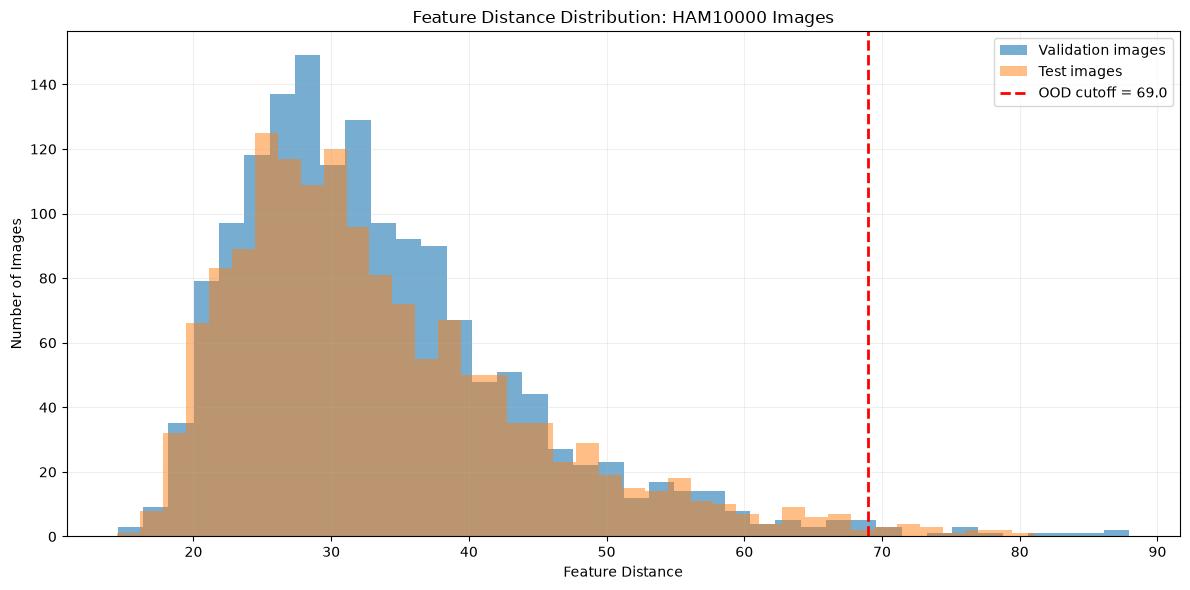

In [9]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 6))

plt.hist(dva, bins=40, alpha=0.6, label="Validation images")
plt.hist(dte, bins=40, alpha=0.5, label="Test images")

plt.axvline(
    thr,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"OOD cutoff = {thr:.1f}"
)

plt.xlabel("Feature Distance")
plt.ylabel("Number of Images")
plt.title("Feature Distance Distribution: HAM10000 Images")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

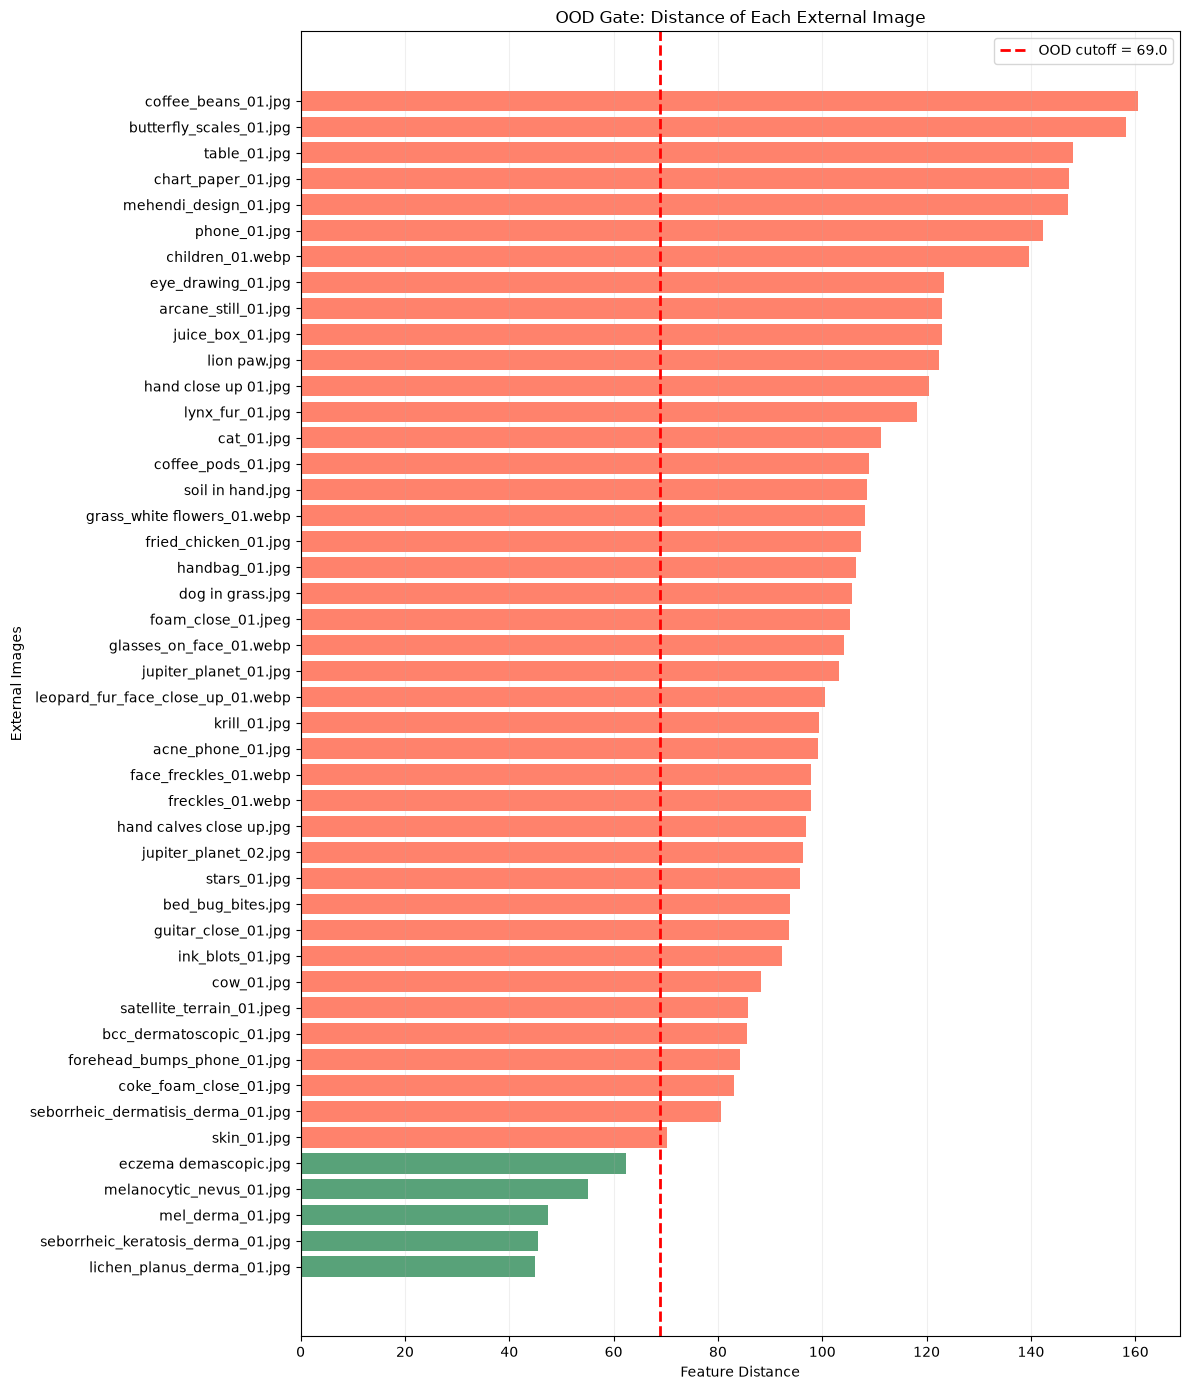

In [10]:
# Sort images by distance
sorted_data = sorted(zip(d_ood, ok_paths))

distances = [x[0] for x in sorted_data]
names = [os.path.basename(x[1]) for x in sorted_data]

# Assign colours based on acceptance/rejection
colors = [
    "seagreen" if d <= thr else "tomato"
    for d in distances
]

plt.figure(figsize=(12, 14))

plt.barh(names, distances, color=colors, alpha=0.8)

plt.axvline(
    thr,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"OOD cutoff = {thr:.1f}"
)

plt.xlabel("Feature Distance")
plt.ylabel("External Images")
plt.title("OOD Gate: Distance of Each External Image")

plt.legend()
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()